In [1]:
import numpy as np
import matplotlib.pyplot as plt   # FIX: sebelumnya "import matplotlib as plt" -> plt.plot tidak akan jalan
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

In [2]:
# parse_dates -> kolom timestamp langsung jadi datetime (bukan string), perlu untuk analisis deret waktu
df = pd.read_csv("sensor_kompresor.csv", parse_dates=["timestamp"])
display(df.info())

# FIX: drop_duplicates() mengembalikan DataFrame baru, jadi harus disimpan ke df
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates()

# Data sensor adalah deret waktu -> pastikan urut waktu dan index bersih
df = df.sort_values("timestamp").reset_index(drop=True)

display(df.describe())
display(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4317 entries, 0 to 4316
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   timestamp   4317 non-null   datetime64[ns]
 1   suhu_ruang  4317 non-null   float64       
 2   suhu_motor  4304 non-null   float64       
 3   getaran     4305 non-null   float64       
 4   tekanan     4305 non-null   float64       
 5   arus        4305 non-null   float64       
 6   rpm         4317 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 236.2 KB


None

Jumlah baris duplikat: 6


,timestamp,suhu_ruang,suhu_motor,getaran,tekanan,arus,rpm
count,4311,4311.000000,4299.000000,4299.000000,4299.000000,4299.000000,4311.000000
mean,2026-09-15 23:48:31.064718080,29.511492,49.704080,1.773688,4.496197,26.970309,864.768499
min,2026-09-01 00:00:00,25.770000,26.880000,0.200000,0.640000,0.300000,0.000000
25%,2026-09-08 11:35:00,27.420000,29.880000,0.278000,1.070000,1.825000,2.000000
50%,2026-09-15 23:10:00,29.510000,61.540000,2.539000,6.810000,43.400000,1474.000000
75%,2026-09-23 12:15:00,31.580000,64.380000,2.767500,7.000000,45.350000,1481.000000
max,2026-09-30 23:50:00,33.380000,88.400000,11.800000,11.900000,79.000000,1499.000000
std,NaN,2.139348,16.480237,1.297941,2.868357,21.066669,728.855104


timestamp      0
suhu_ruang     0
suhu_motor    12
getaran       12
tekanan       12
arus          12
rpm            0
dtype: int64

# Deteksi Anomali Sensor Kompresor

**Alur kerja:**
1. Tentukan status mesin (on/off) dan **fase operasi** (pemanasan, stabil, pendinginan)
2. Tangani missing value
3. Eksplorasi visual
4. Metode A: *robust Z-score* (median & MAD) per fase, statistik univariat
5. Metode B: Isolation Forest, multivariat
6. Bandingkan metode, periksa kejadian tak terjadwal, dan interpretasi

**Temuan awal dari `describe()`:** `rpm` hanya berkisar di dua kelompok (sekitar 0 dan sekitar 1480), jadi kompresor punya dua mode. Statistik gabungan menyesatkan, misal std `arus` = 21 hanya karena campuran mode off (~2 A) dan on (~45 A). Deteksi anomali harus membandingkan data dengan kondisi *normal pada mode/fase yang sama*.

## 1. Status mesin dan fase operasi

- `status`: `rpm > 100` berarti on. Ambang aman karena saat off rpm maksimum 7, saat on minimum 1461.
- Setelah mesin dinyalakan, suhu/tekanan/arus naik bertahap (**pemanasan**); setelah dimatikan, turun bertahap (**pendinginan**). Ini perilaku normal, bukan anomali, dan jika tidak dipisahkan akan terdeteksi sebagai anomali palsu.
- Kita hitung `menit` sejak status terakhir berubah. Dua jam pertama (`RAMP = 120` menit) disebut fase transisi. Data pada jam 00:00 hari pertama tidak punya riwayat sebelumnya, jadi dianggap stabil.

In [3]:
df["status"] = np.where(df["rpm"] > 100, "on", "off")

# sesi = blok berurutan dengan status yang sama
df["ganti"] = df["status"] != df["status"].shift(1)
df["sesi"] = df["ganti"].cumsum()

# menit sejak status terakhir berubah
df["menit"] = (df["timestamp"] - df.groupby("sesi")["timestamp"].transform("min")).dt.total_seconds() / 60
df.loc[df["sesi"] == 1, "menit"] = 9999    # sesi pertama: tidak diketahui awalnya -> anggap stabil

RAMP = 120   # menit; dari data, suhu/arus mulai stabil sekitar 1,5-2 jam setelah on/off
df["fase"] = np.select(
    [(df["status"] == "on") & (df["menit"] < RAMP),
     (df["status"] == "off") & (df["menit"] < RAMP),
     (df["status"] == "on")],
    ["on_pemanasan", "off_pendinginan", "on_stabil"],
    default="off_stabil")

# langkah ke-berapa dalam fase transisi (interval 10 menit); fase stabil dipakai satu kelompok (-1)
df["langkah"] = np.where(df["fase"].isin(["on_pemanasan", "off_pendinginan"]), (df["menit"] // 10).astype(int), -1)

sensor = ["suhu_motor", "getaran", "tekanan", "arus"]   # sensor yang diperiksa anomalinya
print(df["fase"].value_counts())

fase
on_stabil          2184
off_stabil         1458
off_pendinginan     336
on_pemanasan        333
Name: count, dtype: int64


## 2. Missing value

Hanya ~12 baris per sensor (sekitar 0,3%) yang kosong. Karena ini deret waktu dengan interval 10 menit, nilai kosong diisi **interpolasi linear** dari tetangga waktunya (bukan rata-rata global, yang salah untuk mode on/off). `limit=3` membatasi pengisian maksimal 3 titik berturut-turut agar tidak "mengarang" data pada celah panjang. Sisa yang tidak terisi dibuang.

In [4]:
print("Missing sebelum:", df[sensor].isnull().sum().sum())

df[sensor] = df[sensor].interpolate(method="linear", limit=3, limit_area="inside")
df = df.dropna(subset=sensor).reset_index(drop=True)

print("Missing sesudah:", df[sensor].isnull().sum().sum())
print("Jumlah baris akhir:", len(df))

Missing sebelum: 48
Missing sesudah: 0
Jumlah baris akhir: 4310


## 3. Eksplorasi visual

Boxplot per fase: titik di luar "kotak+kumis" adalah kandidat outlier. Perhatikan nilai normal tiap fase sangat berbeda; fase pemanasan/pendinginan terlihat lebar karena nilainya memang sedang berubah.

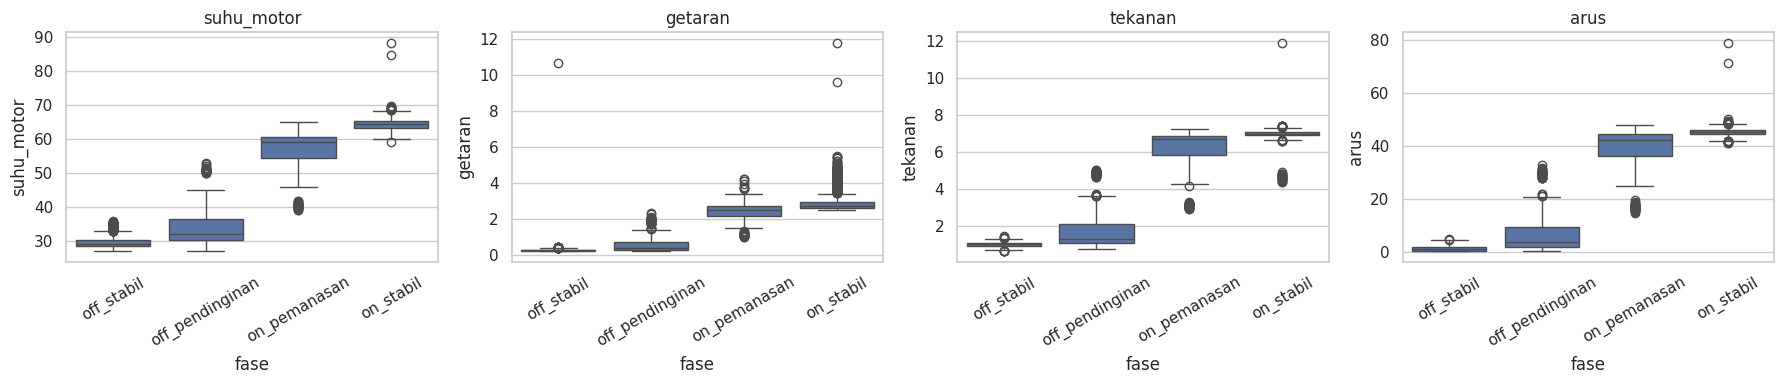

In [5]:
urutan = ["off_stabil", "off_pendinginan", "on_pemanasan", "on_stabil"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, sensor):
    sns.boxplot(data=df, x="fase", y=c, ax=ax, order=urutan)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Deret waktu tiap sensor diwarnai menurut fase. Terlihat siklus harian on/off dan beberapa lonjakan yang menyimpang dari pola umum.

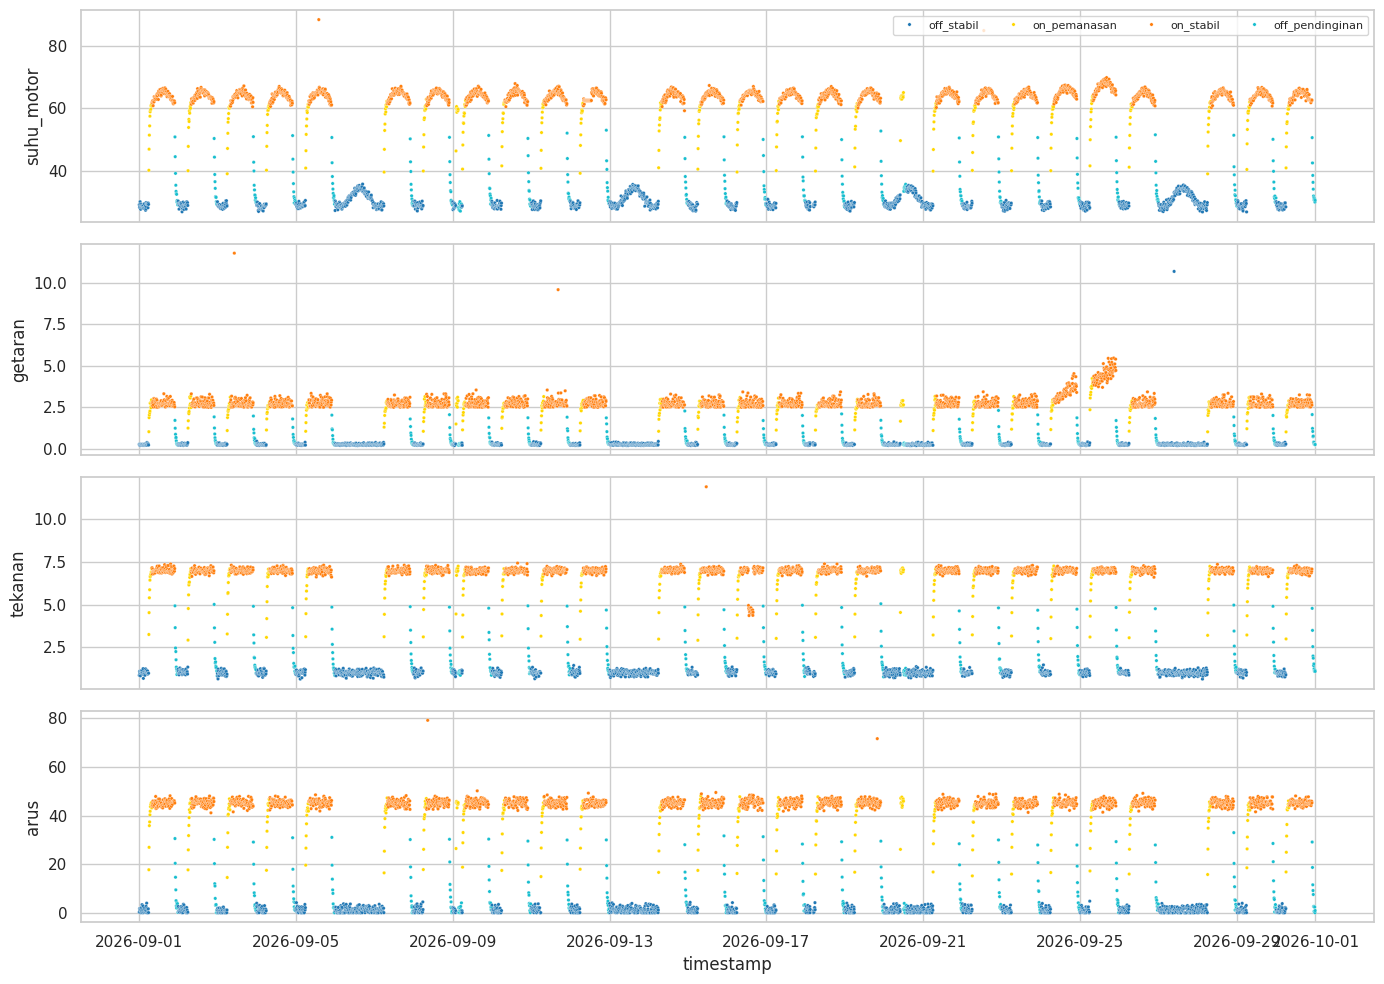

In [6]:
warna = {"off_stabil": "tab:blue", "off_pendinginan": "tab:cyan", "on_pemanasan": "gold", "on_stabil": "tab:orange"}
fig, axes = plt.subplots(len(sensor), 1, figsize=(14, 10), sharex=True)
for ax, c in zip(axes, sensor):
    sns.scatterplot(data=df, x="timestamp", y=c, hue="fase", palette=warna, s=6, ax=ax, legend=(c == sensor[0]))
    ax.set_ylabel(c)
axes[0].legend(loc="upper right", ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## 4. Metode A: Robust Z-score per fase

Untuk tiap sensor, nilai dibandingkan dengan **median kelompoknya**:

`z = 0.6745 * (x - median) / MAD`   (MAD = median |x - median|)

- Kelompok = fase stabil (satu kelompok), atau **(fase, langkah ke-k)** untuk pemanasan/pendinginan. Jadi menit ke-30 setelah menyala dibandingkan dengan menit ke-30 pada hari-hari lain.
- Median/MAD dipakai (bukan mean/std) agar tidak ikut tertarik oleh outlier itu sendiri.
- Ambang `|z| > 3.5` adalah rekomendasi umum (Iglewicz & Hoaglin).
- Batas bawah pada MAD mencegah pembagian dengan nilai hampir nol.

Kelebihan: sederhana, mudah dijelaskan. Kekurangan: melihat satu sensor sekali waktu, sehingga kombinasi yang janggal tidak tertangkap.

In [7]:
def robust_z(s):
    med = s.median()
    mad = (s - med).abs().median()
    mad = max(mad, 0.01 * abs(med) + 1e-6)     # batas bawah supaya tidak meledak
    return 0.6745 * (s - med) / mad

kunci = ["fase", "langkah"]
for c in sensor:
    df[f"z_{c}"] = df.groupby(kunci)[c].transform(robust_z)

ZCUT = 3.5
zcols = [f"z_{c}" for c in sensor]
df["anom_z"] = (df[zcols].abs() > ZCUT).any(axis=1)

print("Anomali per sensor (|z| > 3.5):")
print((df[zcols].abs() > ZCUT).sum())
print("\nTotal baris anomali (robust Z):", df["anom_z"].sum(), f"({df['anom_z'].mean():.1%})")
print(df.groupby("fase")["anom_z"].agg(["sum", "mean"]))

Anomali per sensor (|z| > 3.5):
z_suhu_motor    205
z_getaran       161
z_tekanan        46
z_arus           26
dtype: int64

Total baris anomali (robust Z): 383 (8.9%)
                 sum      mean
fase                          
off_pendinginan   25  0.074405
off_stabil       181  0.124228
on_pemanasan      32  0.096096
on_stabil        145  0.066392


## 5. Metode B: Isolation Forest

Isolation Forest mengisolasi titik dengan pemotongan acak; titik yang cepat terisolasi dianggap anomali. Metode ini **multivariat**: menilai kombinasi sensor sekaligus (misal arus tinggi padahal getaran rendah).

- Fitur yang dipakai adalah **z-score robust dari langkah 4**, bukan nilai mentah. Dengan begitu efek mode/fase sudah dihilangkan dan model hanya melihat penyimpangan dari kondisi normal.
- `contamination=0.02` adalah asumsi ~2% data anomali. Tidak ada label, jadi ini tebakan yang perlu divalidasi secara visual.

In [8]:
X = df[zcols].clip(-20, 20)          # batasi nilai ekstrem agar skala tidak didominasi satu titik
iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=42)
df["anom_if"] = iso.fit_predict(X) == -1          # -1 = anomali
df["skor_if"] = iso.decision_function(X)          # makin rendah = makin anomali

print("Total baris anomali (Isolation Forest):", df["anom_if"].sum(), f"({df['anom_if'].mean():.1%})")
print(df.groupby("fase")["anom_if"].agg(["sum", "mean"]))

Total baris anomali (Isolation Forest): 87 (2.0%)
                 sum      mean
fase                          
off_pendinginan   12  0.035714
off_stabil         2  0.001373
on_pemanasan      15  0.045045
on_stabil         58  0.026557


## 6. Perbandingan kedua metode

Tabel silang menunjukkan kesepakatan antar metode. Baris yang ditandai **kedua** metode adalah anomali paling meyakinkan. Yang ditandai satu metode saja perlu diperiksa manual.

In [9]:
print(pd.crosstab(df["anom_z"], df["anom_if"], rownames=["Robust Z"], colnames=["IsoForest"]))

df["anom_both"] = df["anom_z"] & df["anom_if"]
print("\nDisepakati kedua metode:", df["anom_both"].sum())

IsoForest  False  True 
Robust Z               
False       3927      0
True         296     87

Disepakati kedua metode: 87


### Visualisasi anomali pada deret waktu
Titik merah = ditandai kedua metode (paling meyakinkan), titik hitam = ditandai salah satu saja.

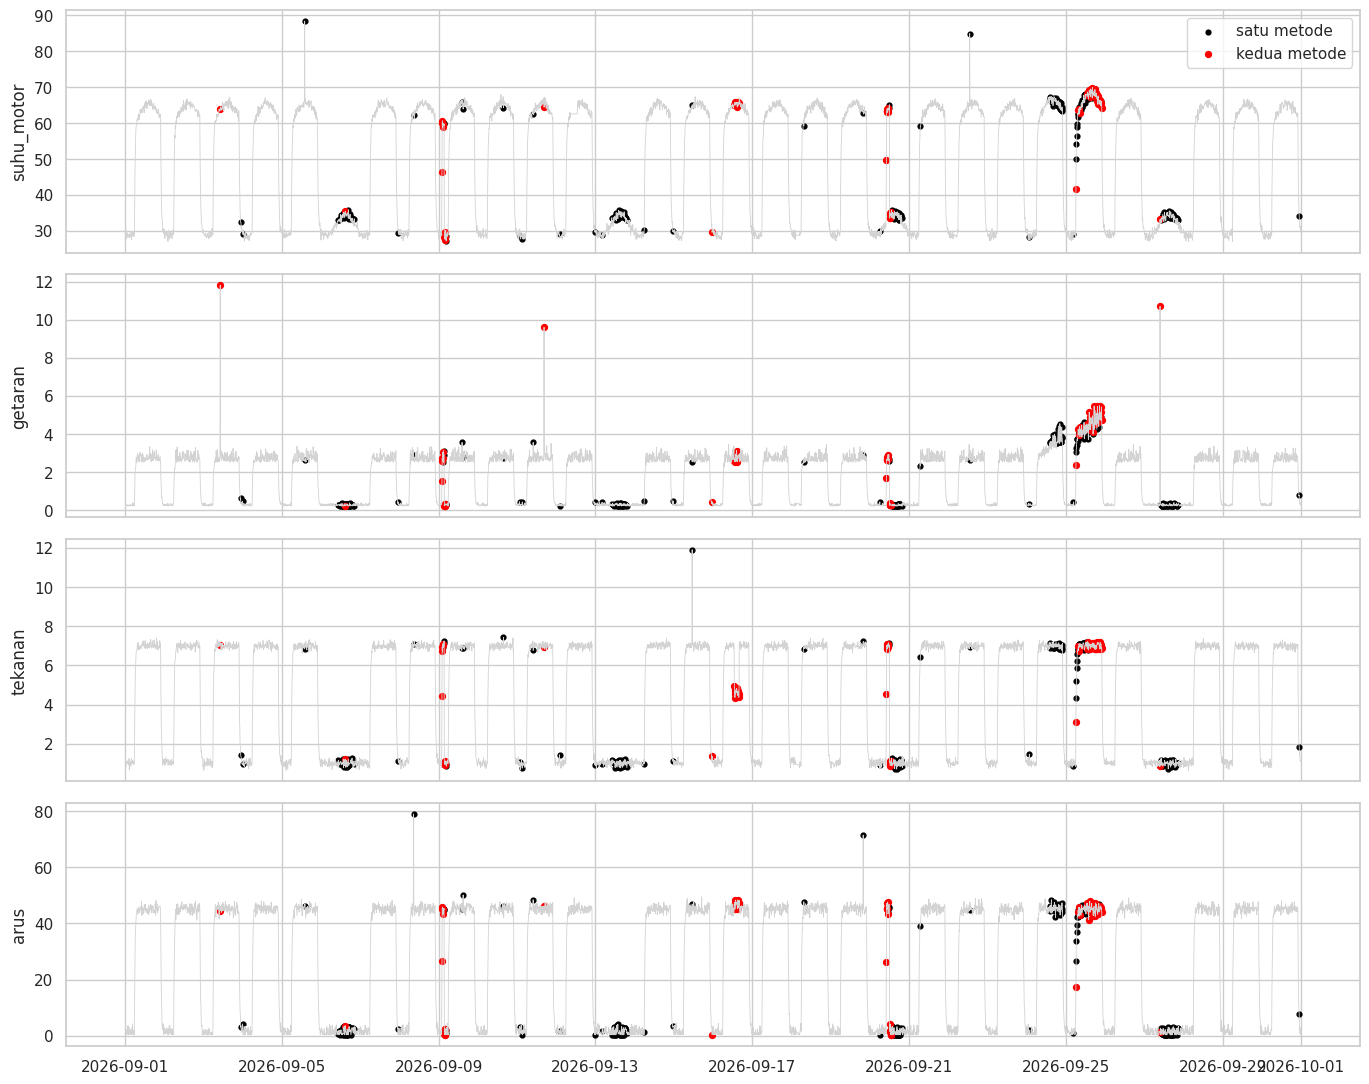

In [10]:
either = (df["anom_z"] | df["anom_if"]) & ~df["anom_both"]

fig, axes = plt.subplots(len(sensor), 1, figsize=(14, 11), sharex=True)
for ax, c in zip(axes, sensor):
    ax.plot(df["timestamp"], df[c], color="lightgray", lw=0.6)
    ax.scatter(df.loc[either, "timestamp"], df.loc[either, c], s=12, color="black", label="satu metode")
    ax.scatter(df.loc[df["anom_both"], "timestamp"], df.loc[df["anom_both"], c], s=18, color="red", label="kedua metode")
    ax.set_ylabel(c)
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

### Kejadian operasional tak terjadwal
Dari pola data, mesin dijadwalkan **menyala 06:00 dan mati 22:00**. Perubahan status di jam lain adalah kejadian di luar jadwal (misal mati/menyala mendadak) dan layak diselidiki, walau tiap titiknya mungkin tidak tampak ekstrem di sensor.

In [11]:
ganti = df[df["ganti"] & (df["sesi"] > 1)].copy()
ganti["jam"] = ganti["timestamp"].dt.strftime("%H:%M")
terjadwal = ganti["jam"].isin(["06:00", "22:00"])
print("Perubahan status terjadwal    :", terjadwal.sum())
print("Perubahan status tak terjadwal:", (~terjadwal).sum())
display(ganti.loc[~terjadwal, ["timestamp", "status", "suhu_motor", "arus", "rpm"]])

Perubahan status terjadwal    : 52
Perubahan status tak terjadwal: 4


,timestamp,status,suhu_motor,arus,rpm
1163,2026-09-09 02:00:00,on,46.39,26.53,1495.0
1172,2026-09-09 03:30:00,off,28.32,0.40,3.0
2786,2026-09-20 10:00:00,on,49.69,26.18,1476.0
2798,2026-09-20 12:00:00,off,33.54,1.79,2.0


### Daftar anomali paling meyakinkan
Diurutkan dari skor Isolation Forest terendah (paling anomali). Gunakan tabel ini untuk pemeriksaan manual dan menentukan jenis anomali.

In [12]:
kolom = ["timestamp", "fase", "suhu_ruang"] + sensor + ["rpm", "skor_if"]
display(df.loc[df["anom_both"], kolom].sort_values("skor_if").head(25))

,timestamp,fase,suhu_ruang,suhu_motor,getaran,tekanan,arus,rpm,skor_if
1172,2026-09-09 03:30:00,off_pendinginan,26.73,28.32,0.219,0.99,0.40,3.0,-0.194292
2798,2026-09-20 12:00:00,off_pendinginan,31.94,33.54,0.245,1.05,1.79,2.0,-0.193759
1173,2026-09-09 03:40:00,off_pendinginan,26.62,28.32,0.222,1.03,2.29,0.0,-0.187391
2799,2026-09-20 12:10:00,off_pendinginan,31.81,33.47,0.349,1.14,1.47,1.0,-0.183350
1164,2026-09-09 02:10:00,on_pemanasan,26.89,60.03,2.709,6.94,45.27,1482.0,-0.178737
2787,2026-09-20 10:10:00,on_pemanasan,30.32,63.20,2.614,7.02,47.12,1473.0,-0.174185
2786,2026-09-20 10:00:00,on_pemanasan,30.35,49.69,1.662,4.54,26.18,1476.0,-0.162840
2788,2026-09-20 10:20:00,on_pemanasan,30.88,63.44,2.659,6.90,44.99,1476.0,-0.151738
1163,2026-09-09 02:00:00,on_pemanasan,26.45,46.39,1.497,4.45,26.53,1495.0,-0.145043
1165,2026-09-09 02:20:00,on_pemanasan,26.40,60.59,2.596,6.71,45.80,1488.0,-0.142251


### Lonjakan sensor ekstrem (spike tunggal)
Anomali jenis lain: **satu sensor** melonjak jauh dari normalnya (`|z| > 15`) sementara sensor lain tampak normal. Ini biasanya gangguan sesaat atau sensor error, bukan perubahan pola operasi.

In [13]:
df["z_maks"] = df[zcols].abs().max(axis=1)
spike = df[df["z_maks"] > 15].sort_values("z_maks", ascending=False)
display(spike[["timestamp", "fase", "suhu_ruang"] + sensor + ["rpm", "z_maks"]])

,timestamp,fase,suhu_ruang,suhu_motor,getaran,tekanan,arus,rpm,z_maks
3791,2026-09-27 09:30:00,off_stabil,29.71,33.09,10.700,0.85,1.24,4.0,234.905867
349,2026-09-03 10:20:00,on_stabil,30.45,64.02,11.800,7.02,44.58,1487.0,41.430305
2082,2026-09-15 11:10:00,on_stabil,31.69,65.06,2.524,11.90,46.94,1489.0,41.313125
1172,2026-09-09 03:30:00,off_pendinginan,26.73,28.32,0.219,0.99,0.40,3.0,34.624333
2798,2026-09-20 12:00:00,off_pendinginan,31.94,33.54,0.245,1.05,1.79,2.0,34.084733
1538,2026-09-11 16:30:00,on_stabil,32.43,64.39,9.600,6.93,46.08,1482.0,31.369966
1059,2026-09-08 08:40:00,on_stabil,28.87,62.11,2.912,7.07,79.00,1472.0,28.070858
2787,2026-09-20 10:10:00,on_pemanasan,30.32,63.20,2.614,7.02,47.12,1473.0,24.217483
2239,2026-09-16 13:20:00,on_stabil,32.65,65.73,2.639,4.36,45.07,1475.0,22.258500
2253,2026-09-16 15:40:00,on_stabil,32.61,65.62,2.781,4.37,46.71,1472.0,22.174187


## 7. Kesimpulan

**Pelajaran metodologi:** data kompresor tidak bisa dianalisis sebagai satu populasi. Setelah dipisah menjadi fase (off stabil, pendinginan, pemanasan, on stabil), pola normal tiap fase jelas dan anomali nyata baru terlihat. Tanpa pemisahan ini, fase pemanasan/pendinginan dan seluruh mode on akan salah ditandai sebagai anomali.

**Perbandingan metode:**
| Metode | Anomali | Sifat |
|---|---|---|
| Robust Z-score (univariat) | 383 baris (8,9%) | Sensitif, banyak penanda ringan (terutama `suhu_motor` & `getaran` saat off yang ikut berfluktuasi mengikuti suhu ruang) |
| Isolation Forest (multivariat) | 87 baris (2,0%) | Lebih selektif; semuanya juga ditandai Z-score |

**Temuan anomali utama (hasil pemeriksaan manual):**
1. **Episode penurunan tekanan, 16 Sep sekitar 13:00-15:50.** Selama ~3 jam, `tekanan` turun ke ~4,5 (normal ~7) saat `arus` justru sedikit naik (~47 A) dan mesin tetap on. Kombinasi ini hanya tertangkap metode multivariat dan mengindikasikan masalah nyata (misal kebocoran udara atau gangguan katup), bukan sensor error.
2. **Kejadian operasi tak terjadwal:** mesin menyala 09 Sep 02:00-03:30 dan 20 Sep 10:00-12:00, di luar jadwal normal 06:00-22:00.
3. **Lonjakan sensor tunggal** yang tidak diikuti sensor lain, sehingga kemungkinan gangguan sesaat/sensor error:
   - `getaran` 11,8 (3 Sep), 9,6 (11 Sep), dan 10,7 saat mesin mati (27 Sep)
   - `suhu_motor` 88,4 (5 Sep) dan 84,9 (22 Sep)
   - `arus` 79 (8 Sep) dan 71,5 (19 Sep)
   - `tekanan` 11,9 (15 Sep)
   - `getaran` 10,7 saat rpm ≈ 0 pada 27 Sep paling mungkin sensor error, karena tidak ada mesin yang berputar.

**Keterbatasan:**
- Tidak ada label anomali, jadi tidak ada akurasi; validasi hanya lewat logika domain dan visualisasi.
- `contamination=0.02`, `RAMP=120`, dan `ZCUT=3.5` adalah parameter yang dipilih, bukan ditentukan dari label. Hasil berubah jika diubah.
- Median/MAD per fase memerlukan beberapa hari data; untuk satu bulan ini cukup, tetapi tidak untuk data yang sangat pendek.

**Pengembangan lanjut:** tambahkan fitur rolling (`diff`, `rolling std`) untuk menangkap perubahan mendadak, atau bandingkan dengan LOF / One-Class SVM.